# 02 – Train-Test-Splitting

## Ziel
Den Iris-Datensatz in Trainings- und Testdaten aufteilen.

## Datensatz
Iris-Datensatz mit 150 Beobachtungen und drei Blumenarten.

In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

In [3]:
print(df.shape)
display(df.head())
print(df.isna().sum())

(150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64


In [4]:
X = df.drop(columns=["target"])
y = df["target"]

print(X.shape)
print(y.shape)

(150, 4)
(150,)


Wenn wir target in X behalten würden, könnte das Modell die richtige Antwort bereits in seinen Eingabedaten sehen.

Das nennt man Data Leakage (Datenleck). Unser Modell könnte dadurch scheinbar hervorragende Ergebnisse erzielen, ohne wirklich gelernt zu haben, wie man Blumen anhand ihrer Messwerte klassifiziert.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(120, 4) (30, 4) (120,) (30,)


# Lektion 25: Stratified Train-Test-Splitting
Quelle: AHMS_MLAging_SplittingData.pdf, Seiten 12–13

Wir haben bisher einen zufälligen Split durchgeführt. Dabei gibt es allerdings ein mögliches Problem.
Was passiert, wenn die Klassen ungleich verteilt werden?
Unser Iris-Datensatz enthält drei Arten mit jeweils 50 Blumen.
Ursprüngliche Klassenverteilung
Setosa (0)

50 Blumen · 33,3 %




Versicolor (1)

50 Blumen · 33,3 %




Virginica (2)

50 Blumen · 33,3 %





Bei einem normalen zufälligen Split könnte das Trainingsset beispielsweise 45 Setosa-, 38 Versicolor- und 37 Virginica-Blumen enthalten.

Das wäre nicht unbedingt problematisch, aber die ursprüngliche Klassenverteilung wäre nicht exakt erhalten geblieben.

Stratified Splitting sorgt dafür, dass die Anteile der verschiedenen Klassen in Trainings- und Testdaten möglichst gleich bleiben.

Variable	Inhalt	Erwartete Dimension
- X_train	Merkmale zum Trainieren	(120, 4)
- X_test	Merkmale zum Testen	(30, 4)
- y_train	Richtige Antworten fürs Training	(120,)
- y_test	Richtige Antworten fürs Testen	(30,)

In [6]:
#train_test_split(
    merkmale,
    zielvariable,
    test_size=0.2,
    random_state=42,
    stratify=zielvariable
    )
# Neue Pandas-Methode: .value_counts()
# Damit kannst du zählen, wie häufig eine Klasse vorkommt.
# series.value_counts()
#series.value_counts(normalize=True)
#erhältst du stattdessen die relativen Häufigkeiten, also die Anteile zwischen 0 und 1.

NameError: name 'merkmale' is not defined

In [7]:
print(y_test.value_counts())
print(y_train.value_counts())

X_train_strat, X_test_strat, y_train_strat, y_test_strat= train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(X_train_strat, X_test_strat, y_train_strat, y_test_strat)

print(X_train_strat.shape, X_test_strat.shape, y_train_strat.shape, y_test_strat.shape)

print(y_test.value_counts())
print(y_test_strat.value_counts())
print(y_train.value_counts())
print(y_train_strat.value_counts())

target
2    11
0    10
1     9
Name: count, dtype: int64
target
1    41
0    40
2    39
Name: count, dtype: int64
     sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
8                  4.4               2.9                1.4               0.2
106                4.9               2.5                4.5               1.7
76                 6.8               2.8                4.8               1.4
9                  4.9               3.1                1.5               0.1
89                 5.5               2.5                4.0               1.3
..                 ...               ...                ...               ...
37                 4.9               3.6                1.4               0.1
2                  4.7               3.2                1.3               0.2
33                 5.5               4.2                1.4               0.2
52                 6.9               3.1                4.9               1.5
3                  4.6      

# Lektion 26 – Feature Scaling

## 1. Lernziele

Nach dieser Lektion kann ich:

- erklären, warum Features skaliert werden.
- den Unterschied zwischen `fit()`, `transform()` und `fit_transform()` erklären.
- den `StandardScaler` aus Scikit-learn verwenden.
- verstehen, wie Data Leakage bei der Skalierung entsteht.

---

## 2. Was ist Feature Scaling?

Feature Scaling ist ein Schritt der Datenvorverarbeitung.

Dabei werden numerische Merkmale auf eine vergleichbare Skala
gebracht.

Das ist für viele Machine-Learning-Algorithmen wichtig,
damit Unterschiede in den Größenordnungen der Features
das Modell nicht unbeabsichtigt beeinflussen.

### Standardisierung

Der `StandardScaler` verwendet folgende Formel:

$$
z = \frac{x-\mu}{\sigma}
$$

Dabei gilt:

| Symbol | Bedeutung |
|---|---|
| $x$ | Ursprünglicher Messwert |
| $\mu$ | Mittelwert |
| $\sigma$ | Standardabweichung |
| $z$ | Standardisierter Messwert |

Nach der Standardisierung haben die Trainingsfeatures:

- einen Mittelwert von ungefähr 0.
- eine Standardabweichung von ungefähr 1.

---

## 3. StandardScaler in Python

Import:

```python
from sklearn.preprocessing import StandardScaler
```

### Wichtige Methoden

| Methode | Funktion |
|---|---|
| `fit()` | Lernt Mittelwert und Standardabweichung |
| `transform()` | Transformiert Werte anhand der gelernten Parameter |
| `fit_transform()` | Kombiniert `fit()` und `transform()` |

### Wichtig: Data Leakage vermeiden

Die Skalierungsparameter dürfen nur aus den Trainingsdaten
gelernt werden.

**Trainingsdaten:** `fit_transform()`

**Testdaten:** `transform()`

Dadurch werden Trainings- und Testdaten mit denselben
Parametern skaliert.

---

## 4. Praxisaufgabe

Verwende unseren stratifizierten Iris-Datensatz.

**Aufgaben:**

- [ ] `StandardScaler` importieren.
- [ ] Ein Scaler-Objekt erstellen.
- [ ] `X_train_strat` standardisieren.
- [ ] `X_test_strat` mit denselben Parametern transformieren.
- [ ] Die Shapes beider Ergebnisse überprüfen.

### Syntax-Hilfe

```python
objekt = Klasse()
objekt.methode(daten)
```

**Hinweis:** Die Ergebnisse sollen in
`X_train_scaled` und `X_test_scaled` gespeichert werden.

---

## 5. Verständnisfragen

1. Warum skalieren wir numerische Features?
2. Was ist der Unterschied zwischen `fit()` und `transform()`?
3. Warum dürfen wir `fit_transform()` nicht erneut
   auf die Testdaten anwenden?
4. Warum skalieren wir die Zielvariable `y` bei unserer
   Iris-Klassifikation nicht?



In [8]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

daten_train_skaliert = scaler.fit_transform(X_train_strat)
daten_test_skaliert = scaler.transform(X_test_strat)

print(daten_test_skaliert)
print(daten_train_skaliert)

print(daten_test_skaliert.shape)
print(daten_train_skaliert.shape)

[[-1.72156775 -0.10821272 -1.40250384 -1.32327558]
 [ 0.30848902 -0.10821272  0.64163131  0.78343181]
 [-1.12449223 -1.45154306 -0.2668732  -0.26992188]
 [-1.00507713 -1.67543145 -0.2668732  -0.26992188]
 [-1.72156775  0.33956406 -1.40250384 -1.32327558]
 [ 0.54731923  0.56345245  0.52806825  0.52009339]
 [-1.48273754  1.23511762 -1.57284844 -1.32327558]
 [-0.52741671  0.78734084 -1.17537771 -1.32327558]
 [ 0.78614944 -0.10821272  0.81197591  1.04677024]
 [-0.52741671 -0.10821272  0.41450518  0.38842418]
 [ 1.74147027 -0.33210111  1.43657276  0.78343181]
 [ 1.26380985  0.11567567  0.75519438  1.44177787]
 [ 0.78614944 -0.10821272  1.1526651   1.31010866]
 [ 0.66673433  0.33956406  0.41450518  0.38842418]
 [-1.00507713  0.78734084 -1.28894078 -1.32327558]
 [-1.00507713  0.56345245 -1.34572231 -1.32327558]
 [-0.04975629  2.13067118 -1.45928537 -1.32327558]
 [-0.2885865  -1.22765467  0.07381599 -0.13825267]
 [ 0.30848902 -0.33210111  0.52806825  0.25675496]
 [ 0.18907392 -0.10821272  0.58

### Lektion 26 – Ergebnisse der Standardisierung

Der `StandardScaler` transformiert unsere vier numerischen
Iris-Merkmale mithilfe von Mittelwert und Standardabweichung.

$$
z = \frac{x-\mu_{\text{train}}}{\sigma_{\text{train}}}
$$

**Interpretation:**

- `z = 0`: Der Wert entspricht dem Trainingsmittelwert.
- `z = 1`: Der Wert liegt eine Standardabweichung darüber.
- `z = -1`: Der Wert liegt eine Standardabweichung darunter.
- `z = 2`: Der Wert liegt zwei Standardabweichungen darüber.

**Wichtige Erkenntnisse:**

- Die ursprünglichen Maßeinheiten (cm) werden durch
  standardisierte Werte ersetzt.
- Die Trainingsfeatures haben nach der Standardisierung
  einen Mittelwert von ungefähr 0 und eine
  Standardabweichung von ungefähr 1.
- Die Testdaten werden mit denselben Parametern transformiert.
- Die Zielvariable `y` wird bei der Klassifikation nicht skaliert.

### Ergebnis der Feature-Skalierung

Die Features wurden mit `StandardScaler` standardisiert.

- `X_train_scaled`: standardisierte Trainingsfeatures
- `X_test_scaled`: standardisierte Testfeatures
- Die Skalierungsparameter stammen ausschließlich aus den Trainingsdaten.
- Die Zielvariablen `y_train_strat` und `y_test_strat` bleiben unverändert.

In [9]:
X_train_scaled = daten_train_skaliert
X_test_scaled = daten_test_skaliert

print(X_train_scaled.shape)
print(X_test_scaled.shape)

print(X_train_scaled.mean(axis=0))
print(X_train_scaled.std(axis=0))

(120, 4)
(30, 4)
[-1.20829273e-15 -2.03679666e-15  4.99600361e-16  1.67458640e-15]
[1. 1. 1. 1.]


# Lektion 27 – K-Nearest Neighbors (KNN)

## 1. Lernziele

Nach dieser Lektion kann ich:

- erklären, wie der KNN-Algorithmus funktioniert.
- verstehen, warum Feature Scaling für KNN wichtig ist.
- ein KNN-Modell in Scikit-learn erstellen.
- ein Modell mit `.fit()` trainieren.
- mit `.predict()` Vorhersagen für neue Daten erzeugen.

---

## 2. Was ist K-Nearest Neighbors?

KNN ist ein Machine-Learning-Algorithmus für Klassifikation
und Regression.

Bei unserer Iris-Klassifikation verwenden wir **Supervised Learning**,
weil wir die richtigen Blumenarten (`y_train_strat`) kennen.

### Wie funktioniert KNN?

Wenn wir eine neue Iris-Blume klassifizieren möchten:

1. KNN vergleicht ihre Merkmale mit den Trainingsblumen.
2. Es berechnet die Abstände zu den Trainingsbeobachtungen.
3. Es findet die `k` nächsten Nachbarn.
4. Es ermittelt, welche Blumenart unter diesen Nachbarn am
   häufigsten vorkommt.
5. Diese Blumenart wird vorhergesagt.

### Beispiel: k = 5

Die fünf nächsten Blumen gehören zu folgenden Arten:

| Nachbar | Iris-Art |
|---|---|
| 1 | Setosa |
| 2 | Versicolor |
| 3 | Setosa |
| 4 | Setosa |
| 5 | Versicolor |

**Vorhersage:** Setosa, weil drei von fünf Nachbarn Setosa sind.

---

## 3. Warum haben wir unsere Daten skaliert?

KNN berechnet Abstände zwischen Datenpunkten.

Wenn ein Feature wesentlich größere Zahlenwerte als ein
anderes besitzt, kann es die Abstandsberechnung dominieren.

Durch Standardisierung bringen wir unsere numerischen
Features auf eine vergleichbare Skala.

Deshalb verwenden wir:

- `X_train_scaled` für das Training.
- `X_test_scaled` für die Vorhersage.
- `y_train_strat` als zugehörige Trainingslabels.
- `y_test_strat` zur späteren Bewertung.

---

## 4. KNN in Scikit-learn

### Neue Klasse

```python
from sklearn.neighbors import KNeighborsClassifier
```

### Wichtige Syntax

**Modell erstellen:**

```python
modell = KNeighborsClassifier(n_neighbors=5)
```

`n_neighbors=5` bedeutet, dass die fünf nächsten Nachbarn
für die Vorhersage berücksichtigt werden.

**Modell trainieren:**

```python
modell.fit(trainingsfeatures, trainingslabels)
```

`.fit()` erhält die Trainingsmerkmale und ihre richtigen Klassen.

Bei KNN bedeutet Training hauptsächlich, dass die
Trainingsbeobachtungen gespeichert werden.

**Vorhersagen erstellen:**

```python
vorhersagen = modell.predict(testfeatures)
```

`.predict()` bestimmt für jede Testbeobachtung eine Klasse.

---

## 5. Praxisaufgabe 27.1

Trainiere deinen ersten KNN-Klassifikator.

- [ ] Importiere `KNeighborsClassifier`.
- [ ] Erstelle ein Modell namens `knn` mit `n_neighbors=5`.
- [ ] Trainiere `knn` mit `X_train_scaled` und `y_train_strat`.
- [ ] Erstelle Vorhersagen für `X_test_scaled`.
- [ ] Speichere diese in `y_pred`.
- [ ] Gib die ersten zehn Vorhersagen aus.
- [ ] Vergleiche sie mit den ersten zehn tatsächlichen Werten aus `y_test_strat`.

**Erwartung:** `y_pred` enthält 30 vorhergesagte Klassen
mit den möglichen Werten 0, 1 und 2.

---

## 6. Verständnisfragen

1. Was bedeutet `k=5`?
2. Warum verwenden wir für KNN standardisierte Features?
3. Was ist der Unterschied zwischen `.fit()` und `.predict()`?
4. Warum benötigen wir beim Training `y_train_strat`,
   aber nicht `y_test_strat`?

In [41]:
from sklearn.neighbors import KNeighborsClassifier
#modell erstellen:
knn = KNeighborsClassifier(n_neighbors = 5)
#Modell trainieren
knn.fit(X_train_scaled, y_train_strat)
#vorhersagen von dem test datenset ergebnissen
y_pred = knn.predict(X_test_scaled)

print(y_pred)

print(y_test_strat.head())
#4.  y test strat ist für wenn wir das fertige modell testen wollen die daten zu train sind dafür da das TRAININGSNODELL ZU BAUEN


[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]
38     0
127    2
57     1
93     1
42     0
Name: target, dtype: int64


### Lektion 27 – Ergebnis: Erstes KNN-Modell

Wir haben einen KNN-Klassifikator mit `k=5` trainiert.

- `fit(X_train_scaled, y_train_strat)` trainiert das Modell.
- `predict(X_test_scaled)` erzeugt Vorhersagen für unbekannte Blumen.
- `y_pred` enthält die vorhergesagten Iris-Arten.
- `y_test_strat` enthält die tatsächlichen Iris-Arten zum Vergleichen.

**Wichtig:** Die Testlabels werden nicht beim Training verwendet,
sondern erst bei der Bewertung des Modells.

In [42]:
print(y_pred[:10])
print(y_test_strat.head(10))

[0 2 1 1 0 1 0 0 2 1]
38     0
127    2
57     1
93     1
42     0
56     1
22     0
20     0
147    2
84     1
Name: target, dtype: int64


# Lektion 28 – Model Evaluation: Accuracy

## 1. Lernziel

Wir möchten herausfinden, wie viele Testbeobachtungen unser
trainiertes KNN-Modell korrekt klassifiziert.

## 2. Was ist Accuracy?

Accuracy beschreibt den Anteil korrekt vorhergesagter Klassen
an allen Vorhersagen.

$$
\text{Accuracy} =
\frac{\text{Anzahl korrekter Vorhersagen}}
{\text{Anzahl aller Vorhersagen}}
$$

Beispiel:

Wenn ein Modell 27 von 30 Blumen richtig erkennt:

$$
\text{Accuracy} = \frac{27}{30} = 0{,}9 = 90\%
$$

## 3. Neue Python-Funktion

```python
from sklearn.metrics import accuracy_score
```

Allgemeine Syntax:

```python
accuracy_score(tatsaechliche_werte, vorhergesagte_werte)
```

Die tatsächlichen Werte stehen immer an erster Stelle.

## 4. Praxisaufgabe

- [ ] Importiere `accuracy_score`.
- [ ] Berechne die Accuracy unseres KNN-Modells.
- [ ] Speichere das Ergebnis in `accuracy`.
- [ ] Gib die Accuracy aus.
- [ ] Interpretiere das Ergebnis als Prozentwert.

In [43]:
from sklearn.metrics import accuracy_score

accuracy= accuracy_score(y_test_strat, y_pred)
print(accuracy)

0.9333333333333333


# Lektion 29 – Confusion Matrix

## Lernziel
Verstehen, welche Klassen unser Modell richtig und falsch vorhersagt.

## Was ist eine Confusion Matrix?

Eine Confusion Matrix vergleicht die tatsächlichen Klassen
mit den vorhergesagten Klassen.

- **Zeilen:** Tatsächliche Iris-Arten
- **Spalten:** Vorhergesagte Iris-Arten
- **Diagonale:** Korrekte Vorhersagen
- **Außerhalb der Diagonale:** Falsche Vorhersagen

Die Summe aller Einträge entspricht der Anzahl der
untersuchten Beobachtungen.

## Python-Syntax

```python
from sklearn.metrics import confusion_matrix

confusion_matrix(tatsaechliche_werte, vorhersagen)
```

## Praxisaufgabe

1. Importiere `confusion_matrix`.
2. Berechne die Matrix für unser KNN-Modell.
3. Speichere sie in `cm`.
4. Gib sie aus und interpretiere die Ergebnisse.

In [51]:
from sklearn.metrics import confusion_matrix

cm=confusion_matrix(y_test_strat, y_pred)

### Lektion 29 – Ergebnisse der Confusion Matrix

Unser KNN-Modell mit `k=5` erreicht eine Accuracy von 93,33 %.

Die Confusion Matrix zeigt:

| Iris-Art | Korrekt erkannt | Falsch erkannt |
|---|---:|---:|
| Setosa | 10 | 0 |
| Versicolor | 10 | 0 |
| Virginica | 8 | 2 |

**Interpretation:**

- Alle Setosa-Blumen wurden korrekt klassifiziert.
- Alle Versicolor-Blumen wurden korrekt klassifiziert.
- Zwei Virginica-Blumen wurden fälschlicherweise als
  Versicolor klassifiziert.

**Erkenntnis:** Die Accuracy zeigt die Gesamtleistung.
Die Confusion Matrix zeigt zusätzlich, welche Klassen
das Modell miteinander verwechselt.

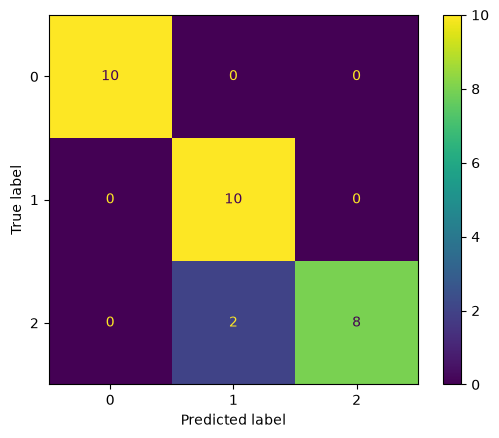

In [52]:
from sklearn.metrics import ConfusionMatrixDisplay


plt=ConfusionMatrixDisplay(confusion_matrix= cm)
plt.plot()

# Lektion 30 – Precision und Recall

## 1. Lernziele

- Precision und Recall unterscheiden.
- False Positives und False Negatives erkennen.
- Beide Kennzahlen aus einer Confusion Matrix berechnen.

## 2. Precision

Precision beantwortet die Frage:

**Wenn das Modell eine bestimmte Iris-Art vorhersagt,
wie häufig ist diese Vorhersage richtig?**

$$
\text{Precision} = \frac{TP}{TP+FP}
$$

- TP (True Positive): Die Art wurde richtig erkannt.
- FP (False Positive): Eine andere Art wurde fälschlicherweise
  als diese Art vorhergesagt.

## 3. Recall

Recall beantwortet die Frage:

**Wie viele der tatsächlich vorhandenen Blumen einer Art
erkennt das Modell richtig?**

$$
\text{Recall} = \frac{TP}{TP+FN}
$$

- TP (True Positive): Die Art wurde richtig erkannt.
- FN (False Negative): Eine Blume dieser Art wurde
  fälschlicherweise einer anderen Art zugeordnet.

## 4. Unterschied

**Precision:** Wie zuverlässig sind die positiven Vorhersagen?

**Recall:** Wie viele der tatsächlich positiven Fälle
haben wir gefunden?

### Precision vs. Recall – Interpretation

**Precision:** Wie viele der als positiv vorhergesagten
Beobachtungen gehören tatsächlich zur betrachteten Klasse?

$$
Precision = \frac{TP}{TP+FP}
$$

**Recall:** Wie viele der tatsächlich positiven
Beobachtungen wurden korrekt erkannt?

$$
Recall = \frac{TP}{TP+FN}
$$

**Beispiel Virginica:**

- TP = 8
- FP = 0
- FN = 2
- Precision = 100 %
- Recall = 80 %

**Merksatz:**
Precision beschreibt die Zuverlässigkeit der Vorhersagen,
Recall die Vollständigkeit der Erkennung.

In [55]:
from sklearn.metrics import precision_score, recall_score

prec_sc= precision_score(y_test_strat, y_pred,average=None)
rec_sc= recall_score(y_test_strat, y_pred,average=None)

print(prec_sc, rec_sc)

[1.         0.83333333 1.        ] [1.  1.  0.8]


### Lektion 30 – Ergebnisse: Precision und Recall

| Iris-Art | Precision | Recall |
|---|---:|---:|
| Setosa | 100 % | 100 % |
| Versicolor | 83,33 % | 100 % |
| Virginica | 100 % | 80 % |

**Interpretation:**

- Setosa wird vollständig und korrekt erkannt.
- Versicolor hat einen Recall von 100 %, weil keine
  tatsächliche Versicolor-Blume übersehen wurde.
- Die Precision von Versicolor beträgt nur 83,33 %,
  weil zwei Virginica-Blumen fälschlicherweise als
  Versicolor klassifiziert wurden.
- Virginica hat eine Precision von 100 %, aber einen
  Recall von 80 %, weil zwei Virginica-Blumen
  nicht erkannt wurden.

4. Lektion 31 – F1-Score

In [58]:
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
print(f1_score(y_test_strat, y_pred,average=None))

print(classification_report(y_test_strat, y_pred))

[1.         0.90909091 0.88888889]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.83      1.00      0.91        10
           2       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



### Macro Average vs. Weighted Average

**Macro Average:**
Berechnet den einfachen Durchschnitt einer Metrik über alle Klassen.
Jede Klasse hat das gleiche Gewicht.

**Weighted Average:**
Berechnet den Durchschnitt einer Metrik unter Berücksichtigung
des Supports (Anzahl tatsächlicher Beobachtungen je Klasse).

**In unserem Iris-Testdatensatz:**
Da jede Klasse 10 Beobachtungen besitzt, sind Macro Average
und Weighted Average gleich.

# Overfitting überprüfen

In [64]:
y_pred_train=knn.predict(X_train_scaled)
print(y_pred_train.shape)
print(y_train_strat.shape)

accuracy_score(y_train_strat, y_pred_train)


(120,)
(120,)


0.975

# Lektion 32 – Overfitting und Underfitting

## 1. Ergebnisse unseres KNN-Modells

| Metrik | Ergebnis |
|---|---:|
| Training Accuracy | 97,5 % |
| Test Accuracy | 93,33 % |
| Differenz | 4,17 Prozentpunkte |

Unser KNN-Modell mit `k=5` klassifiziert:

- 117 von 120 Trainingsblumen richtig.
- 28 von 30 Testblumen richtig.

## 2. Was ist Overfitting?

Overfitting bedeutet, dass ein Modell zu stark an die
Trainingsdaten angepasst ist und deshalb auf unbekannten
Daten deutlich schlechter funktioniert.

Typisches Anzeichen:

**Hohe Training Accuracy, deutlich niedrigere Test Accuracy.**

## 3. Was ist Underfitting?

Underfitting bedeutet, dass ein Modell die relevanten
Zusammenhänge der Daten nicht ausreichend erfasst.

Typisches Anzeichen:

**Niedrige Training Accuracy und niedrige Test Accuracy.**

## 4. Unsere Interpretation

Die Training Accuracy liegt etwas über der Test Accuracy.

Die Differenz ist relativ klein und zeigt allein noch
kein ausgeprägtes Overfitting.

Um die Modellleistung zuverlässiger einzuschätzen,
können wir Cross-Validation verwenden.

# 3. Lektion 33 – Cross-Validation

In [65]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

In [68]:
pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

scores = cross_val_score(
    pipeline,
    X_train_strat,
    y_train_strat,
    cv=5
)


print(scores)

[0.91666667 1.         0.95833333 0.95833333 1.        ]


### Lektion 33 – Ergebnisse der Cross-Validation

Wir haben eine 5-Fold Cross-Validation mit einer Pipeline
aus `StandardScaler` und `KNeighborsClassifier(k=5)`
durchgeführt.

| Fold | Accuracy |
|---|---:|
| 1 | 91,67 % |
| 2 | 100 % |
| 3 | 95,83 % |
| 4 | 95,83 % |
| 5 | 100 % |

**Durchschnittliche Accuracy:** 96,67 %

**Erkenntnisse:**

- Das Modell wird auf fünf unterschiedlichen
  Trainings-/Validierungsaufteilungen untersucht.
- Jede Validierungsgruppe enthält 24 Blumen.
- Die Ergebnisse unterscheiden sich leicht zwischen den Folds.
- Die Pipeline verhindert Data Leakage bei der Skalierung.
- Die Testdaten werden während der Cross-Validation
  nicht verwendet.

In [69]:

print(scores.mean())
print(scores.std())

0.9666666666666668
0.031180478223116186


# Lektion 34 – Hyperparameter-Tuning bei KNN

## 1. Lernziele

- Verstehen, was ein Hyperparameter ist.
- Den Einfluss von `k` auf den KNN-Algorithmus erklären.
- Verschiedene Werte von `k` vergleichen.
- Cross-Validation zur Modellauswahl verwenden.

## 2. Was ist ein Hyperparameter?

Ein Hyperparameter ist eine Einstellung, die wir
vor dem Training eines Modells festlegen.

Bei KNN ist `n_neighbors` ein Hyperparameter.

## 3. Einfluss von k

**Kleines k (z. B. 1):**
- Das Modell berücksichtigt nur wenige Nachbarn.
- Es reagiert empfindlicher auf einzelne Beobachtungen.
- Das Risiko von Overfitting kann steigen.

**Großes k (z. B. 25):**
- Das Modell berücksichtigt viele Nachbarn.
- Einzelne Beobachtungen haben weniger Einfluss.
- Das Risiko von Underfitting kann steigen.

## 4. Ziel

Wir vergleichen verschiedene k-Werte mit
Cross-Validation auf unseren Trainingsdaten.

Die Testdaten bleiben für die abschließende
Modellbewertung reserviert.

### Lektion 34 – Hyperparameter-Tuning mit KNN

Wir testen verschiedene Werte für `n_neighbors`:
`k = 1, 3, 5, 7, 9`.

Für jeden k-Wert wird:
1. Eine Pipeline mit StandardScaler und KNN erstellt.
2. Eine 5-Fold-Cross-Validation durchgeführt.
3. Die durchschnittliche Accuracy berechnet.

**Ziel:** Einen geeigneten k-Wert anhand der
Cross-Validation-Ergebnisse auswählen.

Die Testdaten werden nicht zur Hyperparameter-Auswahl verwendet.

In [72]:
for zahl in [1,3,5,7,9]:
    pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=zahl))

    scores = cross_val_score(
        pipeline,
        X_train_strat,
        y_train_strat,
        cv=5
    )
    print("Accuracy Mean:", scores.mean())
    print("k=", zahl)

Accuracy Mean: 0.9416666666666668
k= 1
Accuracy Mean: 0.9583333333333333
k= 3
Accuracy Mean: 0.9666666666666668
k= 5
Accuracy Mean: 0.9583333333333333
k= 7
Accuracy Mean: 0.9583333333333334
k= 9


# Lektion 35 – Hyperparameter-Tuning visualisieren

## Lernziele

- Ergebnisse einer Schleife in einer Liste speichern.
- Die Methode `.append()` anwenden.
- Unterschiedliche k-Werte grafisch vergleichen.
- Den besten Hyperparameter anhand der Validierung auswählen.

## Ergebnisse speichern

Mit einer Python-Liste können wir mehrere Werte sammeln.

```python
ergebnisse = []
```

Mit `.append()` fügen wir einen neuen Wert am Ende hinzu.

```python
ergebnisse.append(wert)
```

## Warum speichern wir die Accuracy?

Wenn wir die durchschnittliche Accuracy für jeden k-Wert
speichern, können wir anschließend ein Diagramm erstellen.

- X-Achse: Anzahl der Nachbarn (k)
- Y-Achse: Durchschnittliche Cross-Validation-Accuracy

Damit können wir untersuchen, wie sich die Modellleistung
bei unterschiedlichen k-Werten verändert.

In [76]:
ergebnisse=[]

for zahl in [1,3,5,7,9]:
    pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=zahl))

    scores = cross_val_score(
        pipeline,
        X_train_strat,
        y_train_strat,
        cv=5
    )
    mean = scores.mean()
    print("Accuracy Mean is:", mean, "for k=", zahl)
    ergebnisse.append(mean)
   
    
print(ergebnisse)

Accuracy Mean is: 0.9416666666666668 for k= 1
Accuracy Mean is: 0.9583333333333333 for k= 3
Accuracy Mean is: 0.9666666666666668 for k= 5
Accuracy Mean is: 0.9583333333333333 for k= 7
Accuracy Mean is: 0.9583333333333334 for k= 9
[np.float64(0.9416666666666668), np.float64(0.9583333333333333), np.float64(0.9666666666666668), np.float64(0.9583333333333333), np.float64(0.9583333333333334)]


### Lektion 35 – Ergebnisse des Hyperparameter-Tunings

Wir haben fünf unterschiedliche Werte für `n_neighbors`
mit 5-Fold-Cross-Validation getestet.

| k | Accuracy |
|---|---:|
| 1 | 94,17 % |
| 3 | 95,83 % |
| 5 | 96,67 % |
| 7 | 95,83 % |
| 9 | 95,83 % |

**Erkenntnis:** Unter den getesteten Hyperparametern
erreicht `k=5` die höchste durchschnittliche Accuracy.

Die Hyperparameter-Auswahl erfolgte ausschließlich
anhand der Trainingsdaten mit Cross-Validation.

Als Nächstes visualisieren wir den Zusammenhang
zwischen `k` und der Accuracy.

In [78]:
import matplotlib.pyplot as plt

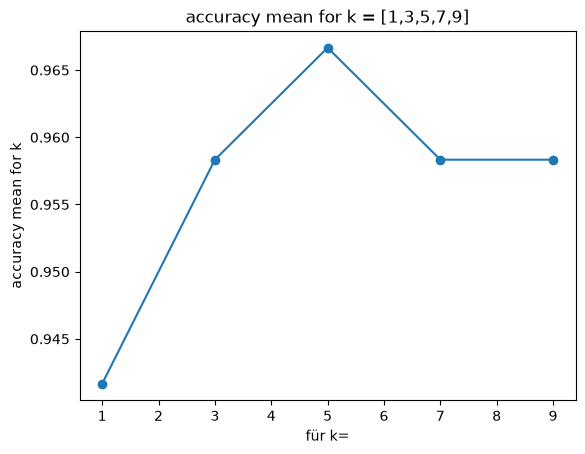

In [79]:
x_werte=[1,3,5,7,9]
y_werte=ergebnisse
plt.plot(x_werte, y_werte, marker="o")
plt.xlabel("für k=")
plt.ylabel("accuracy mean for k")
plt.title("accuracy mean for k = [1,3,5,7,9]")
plt.show()

# Lektion 36 – Besten Hyperparameter automatisch finden

## Lernziel

Den besten k-Wert aus den Cross-Validation-Ergebnissen
automatisch bestimmen.

## Neue Python-Funktionen

### max()

Ermittelt den größten Wert einer Liste.

```python
zahlen = [4, 9, 2, 7]
print(max(zahlen))
```

Ergebnis: `9`

### .index()

Findet die Position eines bestimmten Wertes innerhalb
einer Liste.

```python
zahlen = [4, 9, 2, 7]
print(zahlen.index(9))
```

Ergebnis: `1`

**Wichtig:** Python zählt Positionen ab 0.

Mit der Position können wir anschließend aus einer
zweiten Liste den zugehörigen Wert auswählen.

## Ziel

Wir wollen:
- die höchste durchschnittliche Accuracy finden.
- ihre Position in der Ergebnisliste bestimmen.
- anhand dieser Position den zugehörigen k-Wert ermitteln.

In [91]:
highest_accuracy = max(y_werte)
print(highest_accuracy)

pos = ergebnisse.index(highest_accuracy)
print(pos)

print(x_werte[pos])

0.9666666666666668
2
5


### Lektion 36 – Ergebnis der Hyperparameter-Optimierung

Wir haben unterschiedliche k-Werte mit Cross-Validation
untersucht und den besten Wert automatisch bestimmt.

**Ergebnis:**
- Beste durchschnittliche Accuracy: 96,67 %
- Bester getesteter Hyperparameter: k = 5

**Verwendete Python-Funktionen:**
- `max()` findet den höchsten Wert.
- `.index()` findet dessen Position in einer Liste.
- `liste[position]` gibt das Element an dieser Position zurück.

Bei mehreren identischen Maximalwerten gibt `.index()`
die erste passende Position zurück.

In [92]:
best_k=x_werte[pos]

best_model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))

best_model.fit(X_train_strat, y_train_strat)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['sepal length (cm)','sepal width (cm)','petal length (cm)', 'petal width (cm)']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


# Lektion 38 – Abschließende Modellbewertung

## Ziel

Das mit Cross-Validation ausgewählte KNN-Modell
auf den Testdaten bewerten.

## Ablauf

1. Das trainierte Modell erhält die Testfeatures.
2. Das Modell sagt die Iris-Arten voraus.
3. Wir vergleichen die Vorhersagen mit den tatsächlichen Arten.
4. Wir berechnen Accuracy und Confusion Matrix.

## Wichtig

Die Pipeline enthält bereits den StandardScaler.

Deshalb übergeben wir die unskalierten Testfeatures.
Die Pipeline wendet automatisch die Skalierung mit
den beim Training gelernten Parametern an.

In [102]:

vorhersagen = best_model.predict(X_test_strat)
print(vorhersagen)
accuracy = accuracy_score(y_test_strat, vorhersagen)
print(accuracy)




[0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]
0.9333333333333333


# Lektion 38 – Abschließende Bewertung des KNN-Modells

## Ergebnisse

| Kennzahl | Ergebnis |
|---|---:|
| Bester getesteter k-Wert | 5 |
| Cross-Validation Accuracy | 96,67 % |
| Test Accuracy | 93,33 % |
| Korrekte Testvorhersagen | 28 von 30 |
| Falsche Testvorhersagen | 2 von 30 |

## Erkenntnisse

- Der Hyperparameter `k=5` wurde mit Cross-Validation ausgewählt.
- Das finale Modell besteht aus einer Pipeline mit `StandardScaler` und `KNeighborsClassifier`.
- Die Pipeline wurde auf allen 120 Trainingsblumen trainiert.
- Auf den 30 Testblumen erreicht das Modell eine Accuracy von 93,33 %.
- Die Testdaten werden automatisch mit den beim Training gelernten Parametern standardisiert.